1. IMPORT THƯ VIỆN VÀ ĐỌC DỮ LIỆU

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Đường dẫn từ thư mục gốc của repository
file_path = Path("../data/diabetes.csv")

df = pd.read_csv(file_path)

print("Đọc dữ liệu thành công!")
print("Kích thước dữ liệu:", df.shape)

display(df.head())

Đọc dữ liệu thành công!
Kích thước dữ liệu: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


2. KHẢO SÁT CẤU TRÚC DỮ LIỆU

In [9]:
print("Tên các cột:")
print(df.columns.tolist())

print("\nThông tin kiểu dữ liệu:")
df.info()

print("\nThống kê mô tả:")
display(df.describe())

print("\nSố dòng và số cột:")
print(df.shape)

Tên các cột:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Thông tin kiểu dữ liệu:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Thống kê mô tả:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000



Số dòng và số cột:
(768, 9)


3. KIỂM TRA DỮ LIỆU THIẾU

In [10]:
print("Số giá trị thiếu:")
display(df.isnull().sum())

print("Số dòng trùng lặp:", df.duplicated().sum())

print("\nSố lượng từng nhãn:")
display(df["Outcome"].value_counts().sort_index())

print("\nTỷ lệ từng nhãn (%):")
display(
    (df["Outcome"].value_counts(normalize=True) * 100)
    .sort_index()
    .round(2)
)

Số giá trị thiếu:


Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Số dòng trùng lặp: 0

Số lượng từng nhãn:


Outcome
0    500
1    268
Name: count, dtype: int64


Tỷ lệ từng nhãn (%):


Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64

4. THỐNG KÊ MÔ TẢ ĐẦY ĐỦ

In [11]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

# Trung bình
mean_values = df[numeric_cols].mean()

# Trung vị
median_values = df[numeric_cols].median()

# Mode
mode_values = df[numeric_cols].mode().iloc[0]

# Phương sai mẫu
variance_values = df[numeric_cols].var()

# Độ lệch chuẩn mẫu
std_values = df[numeric_cols].std()

# Giá trị nhỏ nhất, lớn nhất và phạm vi
min_values = df[numeric_cols].min()
max_values = df[numeric_cols].max()
range_values = max_values - min_values

# Các tứ phân vị
q1 = df[numeric_cols].quantile(0.25)
q2 = df[numeric_cols].quantile(0.50)
q3 = df[numeric_cols].quantile(0.75)

# Khoảng tứ phân vị
iqr_values = q3 - q1

summary = pd.DataFrame({
    "Mean": mean_values,
    "Median": median_values,
    "Mode": mode_values,
    "Variance": variance_values,
    "Std": std_values,
    "Min": min_values,
    "Max": max_values,
    "Range": range_values,
    "Q1": q1,
    "Q2": q2,
    "Q3": q3,
    "IQR": iqr_values
})

display(summary.round(3))

,Mean,Median,Mode,Variance,Std,Min,Max,Range,Q1,Q2,Q3,IQR
Pregnancies,3.845,3.000,1.000,11.354,3.370,0.000,17.00,17.000,1.000,3.000,6.000,5.000
Glucose,120.895,117.000,99.000,1022.248,31.973,0.000,199.00,199.000,99.000,117.000,140.250,41.250
BloodPressure,69.105,72.000,70.000,374.647,19.356,0.000,122.00,122.000,62.000,72.000,80.000,18.000
SkinThickness,20.536,23.000,0.000,254.473,15.952,0.000,99.00,99.000,0.000,23.000,32.000,32.000
Insulin,79.799,30.500,0.000,13281.180,115.244,0.000,846.00,846.000,0.000,30.500,127.250,127.250
BMI,31.993,32.000,32.000,62.160,7.884,0.000,67.10,67.100,27.300,32.000,36.600,9.300
DiabetesPedigreeFunction,0.472,0.372,0.254,0.110,0.331,0.078,2.42,2.342,0.244,0.372,0.626,0.382
Age,33.241,29.000,22.000,138.303,11.760,21.000,81.00,60.000,24.000,29.000,41.000,17.000
Outcome,0.349,0.000,0.000,0.227,0.477,0.000,1.00,1.000,0.000,0.000,1.000,1.000


Tính thêm percentile thứ 60:

In [12]:
percentile_60 = df[numeric_cols].quantile(0.60)

print("Percentile 60:")
display(percentile_60.round(3))

Percentile 60:


Pregnancies                   4.000
Glucose                     125.000
BloodPressure                74.000
SkinThickness                27.000
Insulin                      72.200
BMI                          33.700
DiabetesPedigreeFunction      0.454
Age                          33.000
Outcome                       0.000
Name: 0.6, dtype: float64

5. KIỂM TRA CÁC GIÁ TRỊ 0 BẤT THƯỜNG

In [13]:
zero_check_cols = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

available_zero_cols = [
    col for col in zero_check_cols if col in df.columns
]

zero_counts = (df[available_zero_cols] == 0).sum()

print("Số lượng giá trị 0 cần kiểm tra:")
display(zero_counts)

Số lượng giá trị 0 cần kiểm tra:


Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

6. VẼ HISTOGRAM

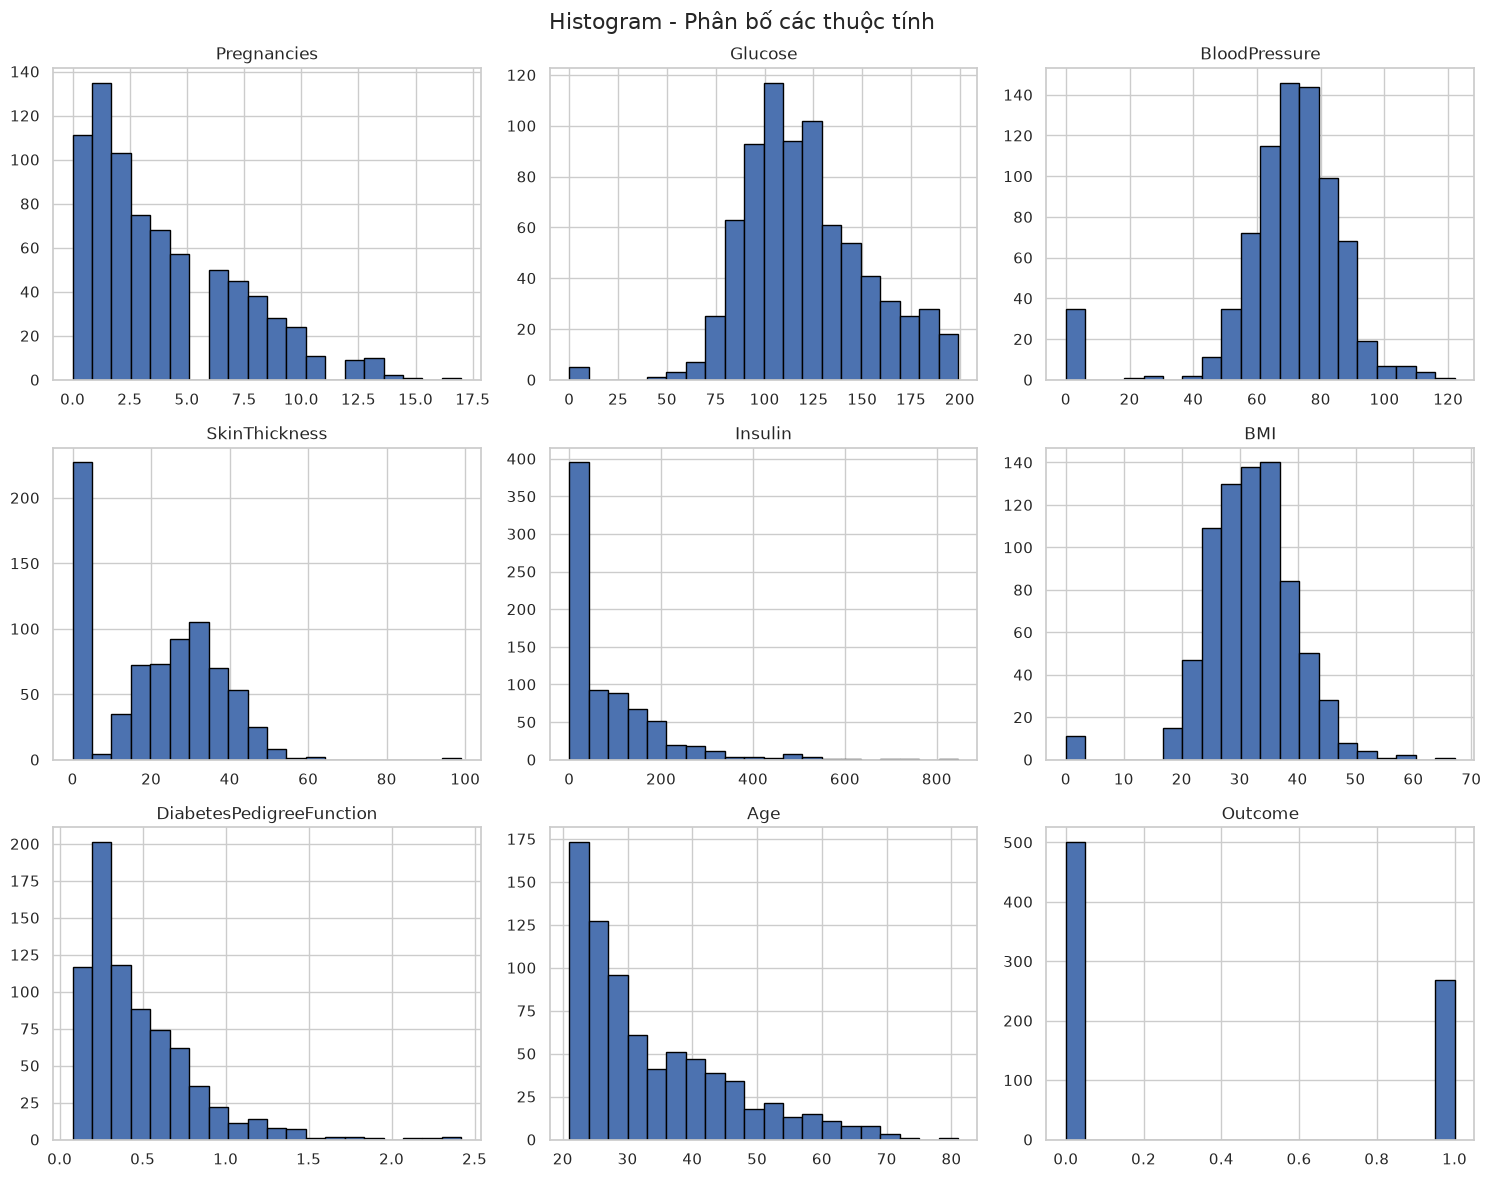

In [14]:
df[numeric_cols].hist(
    bins=20,
    figsize=(15, 12),
    edgecolor="black"
)

plt.suptitle("Histogram - Phân bố các thuộc tính", fontsize=16)
plt.tight_layout()
plt.show()

7. VẼ BOXPLOT

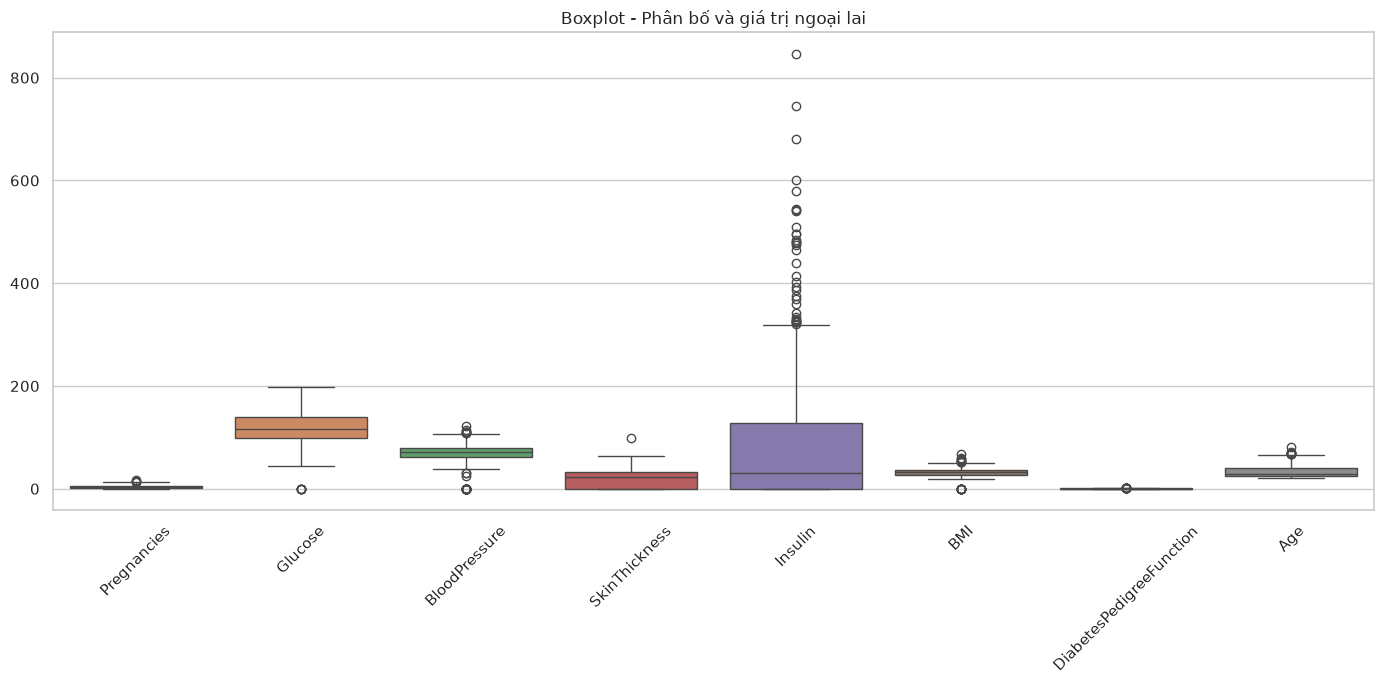

In [15]:
plot_cols = [
    col for col in numeric_cols
    if col != "Outcome"
]

plt.figure(figsize=(14, 7))

sns.boxplot(data=df[plot_cols])

plt.title("Boxplot - Phân bố và giá trị ngoại lai")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

8. TRỰC QUAN HOÁ NHÃN OUTCOME

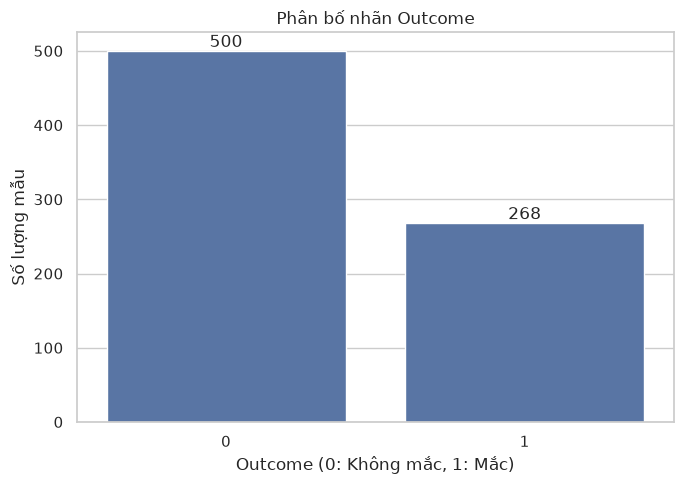

In [16]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df, x="Outcome")

ax.set_title("Phân bố nhãn Outcome")
ax.set_xlabel("Outcome (0: Không mắc, 1: Mắc)")
ax.set_ylabel("Số lượng mẫu")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

9. SO SÁNH THUỘC TÍNH GIỮA 2 NHÓM

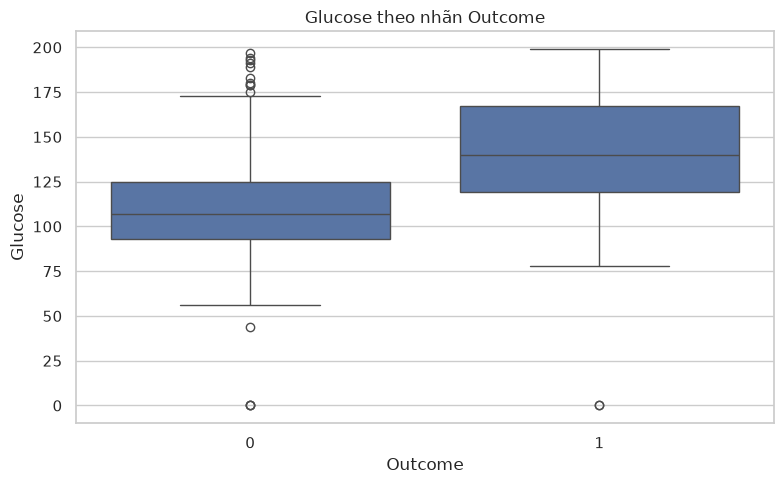

In [17]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Outcome", y="Glucose")

plt.title("Glucose theo nhãn Outcome")
plt.xlabel("Outcome")
plt.ylabel("Glucose")

plt.tight_layout()
plt.show()

Lặp lại với BMI và Age

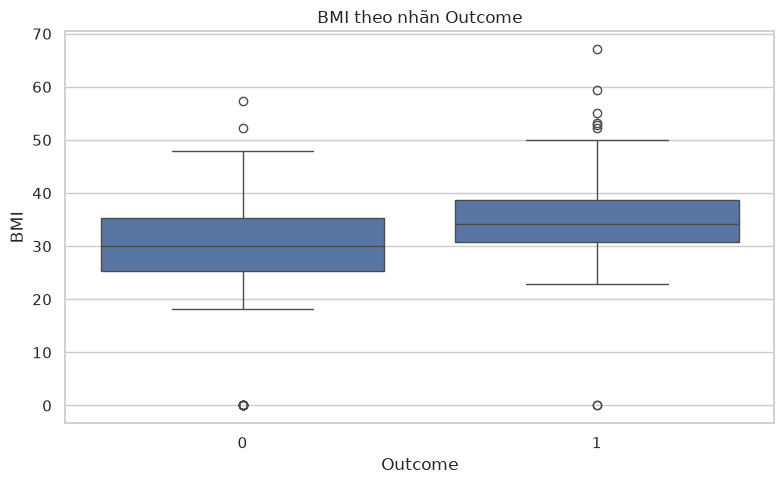

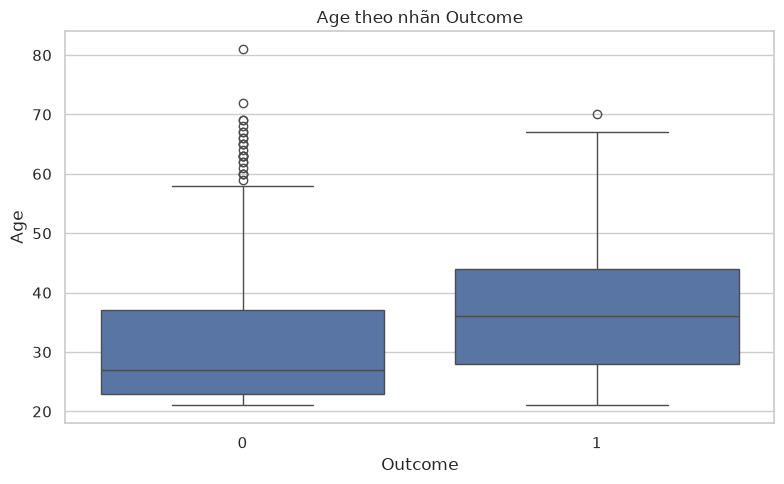

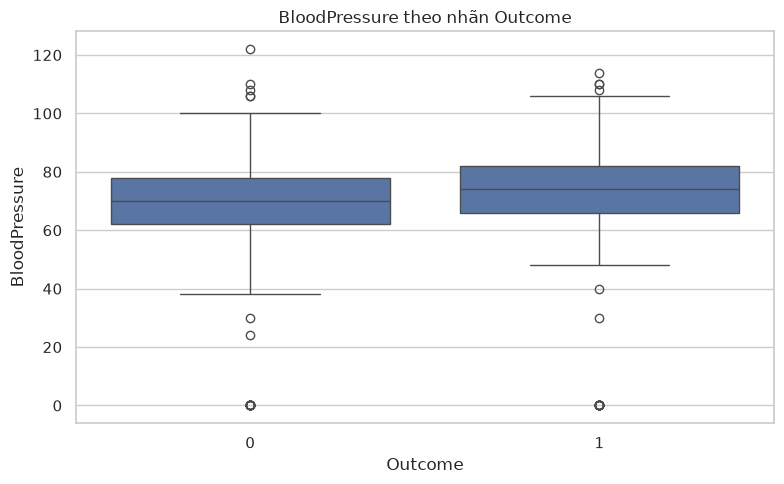

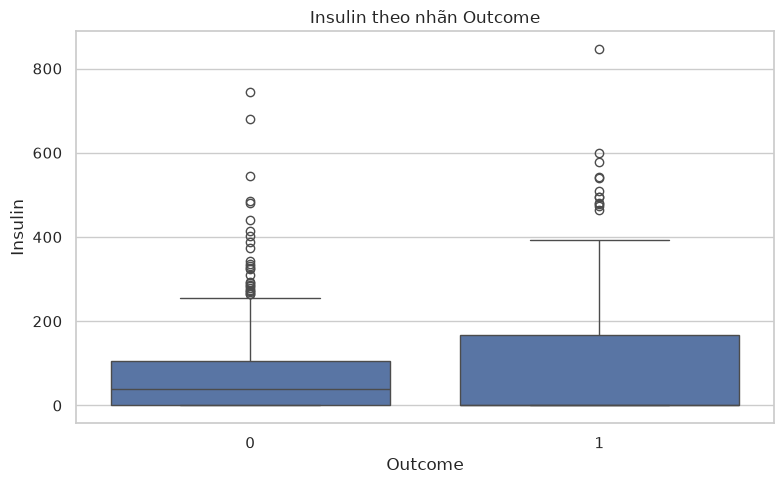

In [18]:
for col in ["BMI", "Age", "BloodPressure", "Insulin"]:
    if col in df.columns:
        plt.figure(figsize=(8, 5))
        sns.boxplot(data=df, x="Outcome", y=col)
        plt.title(f"{col} theo nhãn Outcome")
        plt.tight_layout()
        plt.show()

10. MA TRẬN TƯƠNG QUAN

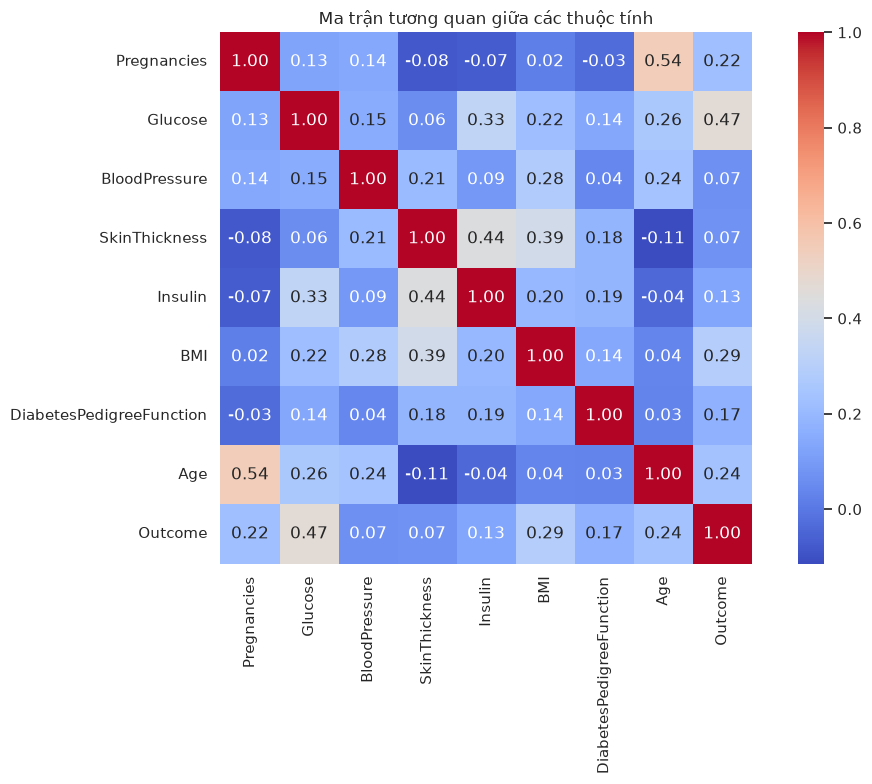

Tương quan với Outcome:


Glucose                     0.466581
BMI                         0.292695
Age                         0.238356
Pregnancies                 0.221898
DiabetesPedigreeFunction    0.173844
Insulin                     0.130548
SkinThickness               0.074752
BloodPressure               0.065068
Name: Outcome, dtype: float64

In [19]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    square=True
)

plt.title("Ma trận tương quan giữa các thuộc tính")
plt.tight_layout()
plt.show()

print("Tương quan với Outcome:")
display(
    corr["Outcome"]
    .drop("Outcome")
    .sort_values(ascending=False)
)

11. XỬ LÝ DỮ LIỆU ĐỂ CHUẨN BỊ CHO MÔ HÌNH

In [20]:
df_clean = df.copy()

# Loại bỏ bản ghi trùng lặp nếu có
df_clean = df_clean.drop_duplicates().copy()

# Các cột mà số 0 có thể biểu thị phép đo thiếu
measurement_cols = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

measurement_cols = [
    col for col in measurement_cols if col in df_clean.columns
]

# Thay 0 bằng NaN ở các cột đo lường đã xác định
df_clean[measurement_cols] = (
    df_clean[measurement_cols].replace(0, np.nan)
)

print("Số giá trị thiếu sau khi kiểm tra số 0:")
display(df_clean.isnull().sum())

Số giá trị thiếu sau khi kiểm tra số 0:


Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64